# 01 — EDA: arXiv AI / ML / NLP papers

Exploratory analysis of the sample used to build the RAG index (default: 10,000 papers in `cs.AI`, `cs.CL`, and `cs.LG`).

If `data/processed/ingest_stats.json` is present, category and year counts over **all matching papers in the snapshot** (before sampling) are shown first, then the same plots are repeated for the 10k sample that was actually indexed.

Jalankan notebook ini dari root project setelah `python scripts/download_data.py` dan (sebaiknya) setelah `python scripts/build_index.py`, agar file `data/processed/papers.jsonl` sudah tersedia.


In [1]:
from collections import Counter
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "configs" / "config.yaml").exists():
    # Allow running the notebook from the notebooks/ directory.
    ROOT = ROOT.parent

SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from arxiv_rag.config import load_config
from arxiv_rag.data.loader import load_processed_papers

cfg = load_config()
cfg.project_root = ROOT
papers_path = cfg.processed_file
stats_path = papers_path.with_name("ingest_stats.json")
print("project root:", ROOT)
print("processed papers:", papers_path, "exists=" + str(papers_path.exists()))
print("ingest stats:", stats_path, "exists=" + str(stats_path.exists()))


project root: /workspace/arxiv-rag-assistant
processed papers: /workspace/arxiv-rag-assistant/data/processed/papers.jsonl exists=True
ingest stats: /workspace/arxiv-rag-assistant/data/processed/ingest_stats.json exists=True


In [2]:
if not papers_path.exists():
    raise FileNotFoundError(
        f"{papers_path} not found. Run `python scripts/build_index.py` "
        "or at least prepare the processed sample first."
    )

papers = load_processed_papers(papers_path)
df = pd.DataFrame(papers)
df["abstract_chars"] = df["abstract"].fillna("").str.len()
df["abstract_words"] = df["abstract"].fillna("").str.split().str.len()
print(f"{len(df):,} papers in the indexed sample")
df.head(3)


10,000 papers in the indexed sample


,arxiv_id,title,abstract,authors,categories,year,doi,update_date,abstract_chars,abstract_words
0,0705.1585,HMM Speaker Identification Using Linear and No...,"Speaker identification is a powerful, non-inva...","Unathi Mahola, Fulufhelo V. Nelwamondo, Tshili...",[cs.LG],2007,,2007-05-23,843,115
1,0706.0022,Modeling Computations in a Semantic Network,Semantic network research has seen a resurgenc...,Marko A. Rodriguez and Johan Bollen,[cs.AI],2007,,2021-08-23,914,137
2,0710.3561,Stationary probability density of stochastic s...,A method for the construction of approximate a...,Arturo Berrones,"[cond-mat.stat-mech, cs.AI, cs.NE]",2007,10.1088/1742-5468/2008/01/P01013,2008-01-30,452,65


## Snapshot-level counts (before sampling)

These numbers describe every paper in the Kaggle snapshot that matches the configured categories (and optional year bounds), not just the 10k sample.


In [3]:
stats = None
if stats_path.exists():
    stats = json.loads(stats_path.read_text(encoding="utf-8"))
    print(f"Raw records scanned: {stats.get('raw_scanned'):,}")
    print(f"Papers matching filters: {stats.get('matched'):,}")
    print(f"Papers retained after sampling: {stats.get('retained'):,}")
    print("Category counts (multi-label, a paper may appear in more than one):")
    print(stats.get("category_counts"))
else:
    print("ingest_stats.json is not available; snapshot-level plots will be skipped.")


Raw records scanned: 3,252,452
Papers matching filters: 488,660
Papers retained after sampling: 10,000
Category counts (multi-label, a paper may appear in more than one):
{'cs.AI': 212730, 'cs.CL': 125322, 'cs.LG': 299024}


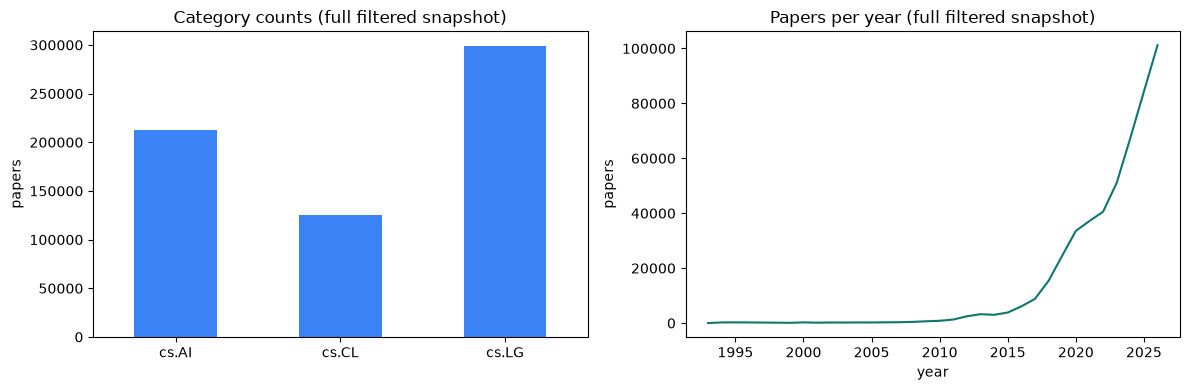

In [4]:
if stats:
    cat = pd.Series(stats["category_counts"]).sort_index()
    years = pd.Series({int(k): v for k, v in stats["year_counts"].items()}).sort_index()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    cat.plot(kind="bar", ax=axes[0], color="#3b82f6", rot=0)
    axes[0].set_title("Category counts (full filtered snapshot)")
    axes[0].set_ylabel("papers")
    axes[0].set_xlabel("")

    years.plot(ax=axes[1], color="#0f766e")
    axes[1].set_title("Papers per year (full filtered snapshot)")
    axes[1].set_xlabel("year")
    axes[1].set_ylabel("papers")
    fig.tight_layout()
    plt.show()


## Indexed sample (default ~10,000 papers)

This is the actual corpus stored in the FAISS + BM25 indexes.


In [5]:
# Multi-label: explode categories, keep only the three target codes.
target = set(cfg.data.categories)
exploded = (
    df.explode("categories")
    .loc[lambda x: x["categories"].isin(target)]
)
cat_sample = exploded["categories"].value_counts().reindex(sorted(target)).fillna(0).astype(int)
print("Category counts in the sample (multi-label):")
print(cat_sample.to_string())
print()
print(df["year"].describe().to_string())


Category counts in the sample (multi-label):
categories
cs.AI    4359
cs.CL    2596
cs.LG    6112

count    10000.000000
mean      2022.645700
std          3.557757
min       1994.000000
25%       2021.000000
50%       2024.000000
75%       2025.000000
max       2026.000000


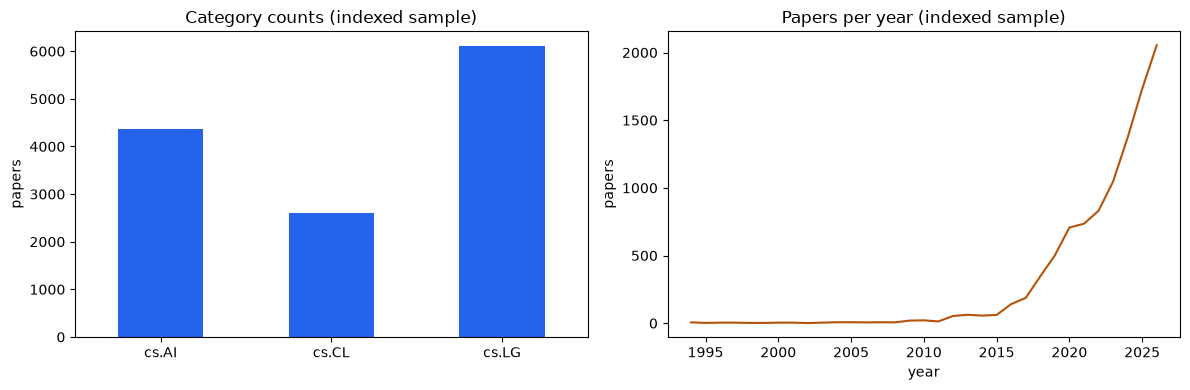

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cat_sample.plot(kind="bar", ax=axes[0], color="#2563eb", rot=0)
axes[0].set_title("Category counts (indexed sample)")
axes[0].set_ylabel("papers")
axes[0].set_xlabel("")

year_counts = df["year"].dropna().astype(int).value_counts().sort_index()
year_counts.plot(ax=axes[1], color="#b45309")
axes[1].set_title("Papers per year (indexed sample)")
axes[1].set_xlabel("year")
axes[1].set_ylabel("papers")
fig.tight_layout()
plt.show()


## Abstract length

Most arXiv abstracts fit in a single chunk at the default `max_chars=1600` setting. Longer abstracts are split with overlap.


       abstract_chars  abstract_words
count         10000.0         10000.0
mean           1252.8           174.4
std             343.2            47.7
min             116.0            15.0
25%            1010.0           141.0
50%            1258.0           173.0
75%            1496.0           206.0
max            2042.0           321.0

Papers whose title+abstract likely need more than one 1600-char chunk: 2,489


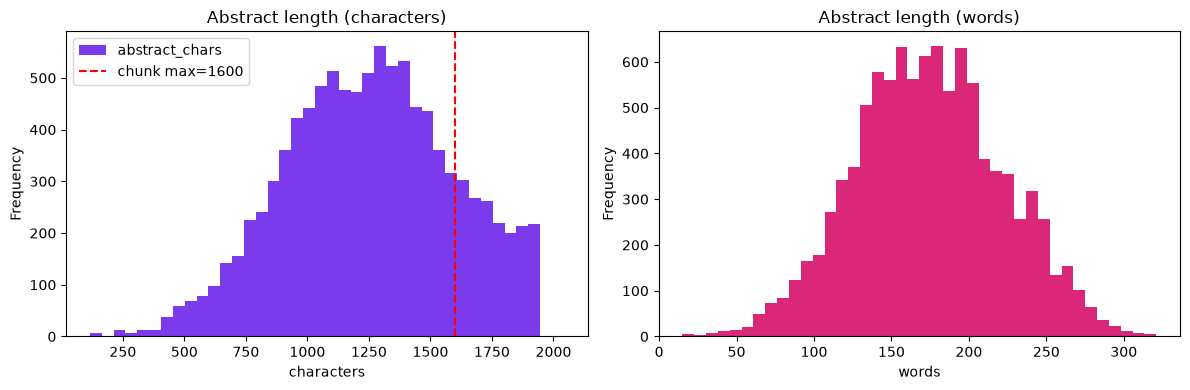

In [7]:
print(df[["abstract_chars", "abstract_words"]].describe().round(1).to_string())
print()
max_chars = cfg.chunking.max_chars
n_over = int(((df["abstract_chars"] + df["title"].fillna("").str.len() + 20) > max_chars).sum())
print(f"Papers whose title+abstract likely need more than one {max_chars}-char chunk: {n_over:,}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["abstract_chars"].plot(kind="hist", bins=40, ax=axes[0], color="#7c3aed")
axes[0].axvline(max_chars, color="red", linestyle="--", label=f"chunk max={max_chars}")
axes[0].set_title("Abstract length (characters)")
axes[0].set_xlabel("characters")
axes[0].legend()

df["abstract_words"].plot(kind="hist", bins=40, ax=axes[1], color="#db2777")
axes[1].set_title("Abstract length (words)")
axes[1].set_xlabel("words")
fig.tight_layout()
plt.show()


## Sample titles

A few randomly selected papers from the indexed sample, for a qualitative sanity check.


In [8]:
cols = ["arxiv_id", "year", "categories", "title"]
df.sample(8, random_state=42)[cols].sort_values("year")


,arxiv_id,year,categories,title
576,1711.01343,2017,"[cs.LG, cs.NE]",Accelerating Training of Deep Neural Networks ...
1731,2006.05720,2020,"[cs.LG, stat.ML]",Extrapolation for Large-batch Training in Deep...
4742,2312.07141,2023,[cs.CL],Multilingual large language models leak human ...
4684,2311.13843,2023,"[cs.AI, cs.LG, cs.MS]",Exact Combinatorial Optimization with Temporo-...
4521,2310.07931,2023,"[cs.AI, cs.CL, cs.CV, cs.LG]",D2 Pruning: Message Passing for Balancing Dive...
5202,2404.13669,2024,"[cs.DC, cs.LG, cs.MA, math.OC]",Rate Analysis of Coupled Distributed Stochasti...
6252,2501.15942,2025,[cs.LG],TimeHF: Billion-Scale Time Series Models Guide...
6340,2502.11051,2025,"[cs.AI, cs.CL]",MMUnlearner: Reformulating Multimodal Machine ...
